# UTS KLASIFIKASI

## BUSINESS UNDERSTANDING

Proyek klasifikasi tutupan lahan (*Land Use Land Cover*) wilayah Jawa Timur ini dikembangkan untuk merespons tingginya dinamika alih fungsi lahan akibat urbanisasi dan pertumbuhan ekonomi. Mengingat pemantauan manual di lapangan sangat tidak efisien dan memakan biaya tinggi, sistem ini memanfaatkan penginderaan jauh dari citra satelit Sentinel-2 untuk memetakan permukaan bumi secara otomatis, cepat, dan berkala.

Dengan mengekstrak 8 fitur andalan yang terdiri dari 6 pita spektral (Band 2, 3, 4, 8A, 11, 12) serta indeks komputasi tambahan berupa NDVI (Kerapatan Vegetasi) dan NDWI (Indeks Kebasahan Air), model *Machine Learning* Random Forest yang dibangun mampu mengatasi kebingungan visual pada citra standar RGB. Sistem dapat membedakan secara presisi objek-objek yang sering kali mengecoh mata manusia, seperti memisahkan hutan daratan biasa dengan hutan mangrove di pesisir, atau membedakan lahan pertanian produktif dengan area terbangun (*built-up area*).

Hasil akhir dari prediksi model ini disajikan dalam bentuk *dashboard* peta geospasial interaktif. Melalui platform ini, para pengambil kebijakan dapat langsung memantau, memfilter, dan menganalisis distribusi tutupan lahan secara *real-time* demi mendukung perencanaan tata ruang serta pelestarian lingkungan yang lebih akurat dan berbasis data (*data-driven*).

## DATA UNDERSTANDING

Tahap Data Understanding bertujuan untuk memahami karakteristik, distribusi, dan rincian data spektral yang diekstrak, serta mengidentifikasi potensi masalah pada data sebelum masuk ke tahap pemodelan.

Membaca data spasial dari GeoJSON...
Mengambil data satelit Sentinel-2...
Mengekstrak data piksel sampel ke CSV...
Ekstraksi CSV Selesai.
Mulai mengunduh TIF Jawa Timur Utuh... (Proses ini memakan waktu)


C:\Users\mappattiro\kal\kal\Lib\site-packages\geemap\common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)
C:\Users\mappattiro\kal\kal\Lib\site-packages\geedim\tile.py:172: RuntimeWarning: Consider adjusting the image bounds, resolution or data type with 'prepareForExport()' to reduce the export size: 17.6GB.
  self._validate_image(image)


  0%|          |0/4480 tiles [00:00<?]

Unduhan TIF Jawa Timur Selesai.
Memuat dan menganalisis dataset CSV...
Total data: 15014 baris, 10 kolom

Distribusi Kelas:
 Class
Hutan             4277
Hutan Mangrove    3444
Sawah             2672
Bangunan          2389
Perairan          2232


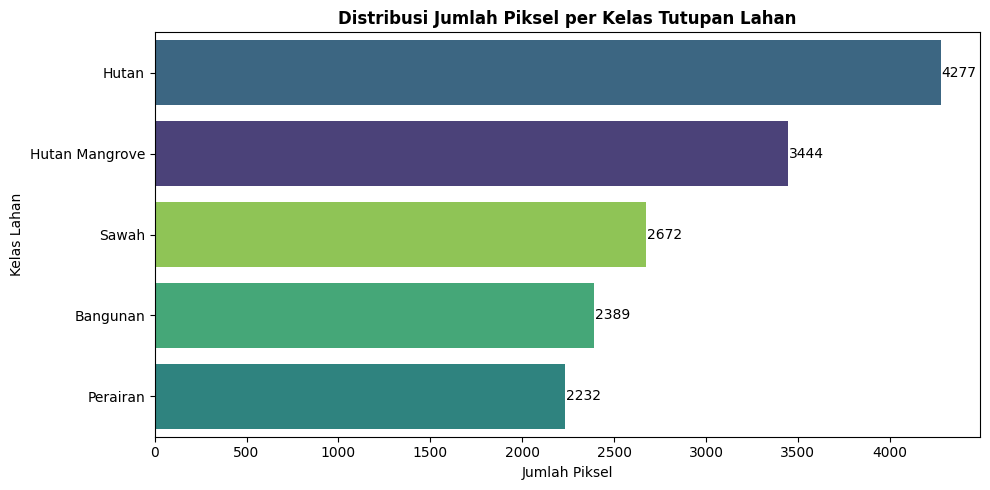

In [12]:
import os
import json
import pandas as pd
import urllib.request
import ee
import geemap
import matplotlib.pyplot as plt
import seaborn as sns

file_csv = 'dataset_training.csv'
file_tif = 'Sentinel2_Jatim_Utuh.tif'
file_geojson = 'Update22.geojson'

# Inisialisasi API Google Earth Engine
if not (os.path.exists(file_csv) and os.path.exists(file_tif)):
    try:
        ee.Initialize()
    except Exception:
        ee.Authenticate()
        ee.Initialize()

    print("Membaca data spasial dari GeoJSON...")
    with open(file_geojson, 'r') as f:
        geojson_data = json.load(f)
        
    pemetaan_kelas = {
        'Hutan Mangrove\n': 'Hutan Mangrove',
        'Hutan biasa (Forest)': 'Hutan',
        'Lautan, danau, perairan ( water body)': 'Perairan',
        'Lahan Pertanian': 'Sawah',   
        'bangunan': 'Bangunan'        
    }
    
    jatim_feature = None
    fitur_valid = []
    
    # Memilah isi GeoJSON
    for i, feature in enumerate(geojson_data['features']):
        if 'Class' in feature['properties']:
            nama_asli = feature['properties']['Class']
            
            # SOLUSI: Gunakan .strip() untuk membuang spasi/enter gaib (\n) di akhir teks
            if nama_asli.strip() == 'JAWA TIMUR':
                jatim_feature = feature
            elif nama_asli in pemetaan_kelas:
                feature['properties']['Class'] = pemetaan_kelas[nama_asli]
                feature['properties']['poly_id'] = i
                fitur_valid.append(feature)
                
    if jatim_feature is None:
        raise ValueError("ERROR: Poligon dengan Class 'JAWA TIMUR' tidak ditemukan di dalam GeoJSON!")

    roi_jatim = ee.Feature(jatim_feature).geometry() 
    fc_training = ee.FeatureCollection(fitur_valid)  
    
    print("Mengambil data satelit Sentinel-2...")
    s2_base = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
        .filterBounds(roi_jatim) \
        .filterDate('2025-01-01', '2026-09-30') \
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)) \
        .median() \
        .select(['B2', 'B3', 'B4', 'B8A', 'B11', 'B12'])

    ndvi = s2_base.normalizedDifference(['B8A', 'B4']).rename('NDVI')
    ndwi = s2_base.normalizedDifference(['B3', 'B8A']).rename('NDWI')
    s2_final = s2_base.addBands([ndvi, ndwi])
    
    # Ekstraksi CSV
    if not os.path.exists(file_csv):
        print("Mengekstrak data piksel sampel ke CSV...")
        sampled = s2_final.sampleRegions(
            collection=fc_training, properties=['Class', 'poly_id'], scale=30, tileScale=16, geometries=False
        )

        url = sampled.getDownloadURL(filetype='csv', selectors=['Class', 'poly_id', 'B2', 'B3', 'B4', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI'])
        urllib.request.urlretrieve(url, file_csv)
        
        df_temp = pd.read_csv(file_csv).dropna()
        df_temp = df_temp[~((df_temp['Class'].isin(['Hutan Mangrove', 'Hutan', 'Sawah'])) & (df_temp['NDWI'] > 0.1))]
        df_temp = df_temp.rename(columns={
            'B2': 'Band_2', 'B3': 'Band_3', 'B4': 'Band_4', 
            'B8A': 'Band_8A', 'B11': 'Band_11', 'B12': 'Band_12'
        })
        df_temp.to_csv(file_csv, index=False)
        print("Ekstraksi CSV Selesai.")

    # Ekstraksi TIF
    if not os.path.exists(file_tif):
        print("Mulai mengunduh TIF Jawa Timur Utuh... (Proses ini memakan waktu)")
        s2_clipped = s2_final.clip(roi_jatim) 
        
        geemap.download_ee_image(
            s2_clipped, 
            filename=file_tif, 
            scale=30, 
            region=roi_jatim,
            crs='EPSG:4326'
        )
        print("Unduhan TIF Jawa Timur Selesai.")

print("Memuat dan menganalisis dataset CSV...")
df = pd.read_csv(file_csv)
distribusi = df['Class'].value_counts()

print(f"Total data: {df.shape[0]} baris, {df.shape[1]} kolom")
print("\nDistribusi Kelas:\n", distribusi.to_string())

plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    data=df, 
    y='Class', 
    order=distribusi.index, 
    palette='viridis',
    hue='Class',
    legend=False
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', (width + 5, p.get_y() + p.get_height() / 2.), ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

### Sumber Data dan Skenario Ekstraksi

Data diekstrak berdasarkan sekumpulan area *Region of Interest* (ROI) berformat GeoJSON yang mencakup poligon sampel kelas lahan dan poligon batas wilayah batas Provinsi Jawa Timur. Nilai piksel diekstrak menggunakan layanan komputasi *cloud* Google Earth Engine dengan parameter ekstraksi sebagai berikut:

- **Koleksi Citra:** Sentinel-2 Level-2A Surface Reflectance (*Harmonized*).
- **Rentang Waktu:** 1 Januari 2025 hingga 30 September 2026.
- **Toleransi Awan:** Maksimum **10%** (sangat jernih). Reduksi awan tambahan dilakukan secara otomatis menggunakan metode *Median Reducer* (mengambil nilai spektral tengah yang paling bersih dari seluruh rentang waktu tersebut).
- **Pita Spektral & Indeks:** Menggunakan 6 band mentah (Band 2, 3, 4, 8A, 11, 12) serta menambahkan 2 pita komputasi indeks, yakni NDVI (Kerapatan Vegetasi) dan NDWI (Kebasahan/Air).
- **Resolusi Spasial (*Scale*):** 30 meter per piksel. Resolusi ini ditetapkan untuk memastikan objek dengan area sempit (seperti Bangunan) tidak hilang tertelan *grid* spasial, sekaligus menjaga beban komputasi tetap rasional untuk area skala provinsi.
- **Pembersihan Noise Otomatis:** Diterapkan filter anomali spasial yang membuang piksel-piksel "siluman" di dalam poligon daratan (Hutan, Hutan Mangrove, Sawah) yang secara keliru memiliki nilai indeks air terlalu tinggi (NDWI > 0.1).

**Skenario Unduhan Ganda (Dual Extraction)**
Untuk menghindari limitasi memori (*memory limit*) dan memisahkan kebutuhan fase proyek, data diunduh melalui dua jalur berbeda:
1. **Data Tabular (`dataset_training.csv`):** Mengekstrak kemurnian nilai piksel hanya pada titik-titik poligon sampel (Hutan, Mangrove, Sawah, Bangunan, Perairan) melalui URL *download* khusus sebagai bahan ajar (*training*) algoritma Machine Learning.
2. **Data Raster Spasial (`Sentinel2_Jatim_Utuh.tif`):** Mengunduh peta citra utuh yang dipotong (*clipping*) secara presisi mengikuti bentuk lekukan poligon "JAWA TIMUR". File biner berukuran besar ini disiapkan khusus sebagai kanvas kosong untuk tahap *Deployment* (Inferensi Spasial).

### Karakteristik Fitur (Spektral Band & Indeks)

Dataset ini menggunakan 6 variabel spektral independen berupa pantulan cahaya (*reflectance*) dari instrumen satelit Sentinel-2, ditambah 2 fitur hasil kalkulasi indeks tutupan lahan. Pemilihan 8 fitur ini secara spesifik bertujuan untuk memisahkan 5 kelas lahan secara optimal:

| Nama Fitur | Fungsi Klasifikasi |
|---|---|
| **Band 2 (Blue) & Band 3 (Green)** | Sangat sensitif terhadap pantulan air. Kehadiran dua band ini krusial untuk membedakan kelas Perairan dengan objek daratan yang gelap (seperti aspal padat atau bayangan awan). |
| **Band 4 (Red)** | Menyerap klorofil tanaman secara kuat. Sangat esensial untuk mendeteksi tingkat kerapatan daun dan memisahkan area vegetasi dari non-vegetasi. |
| **Band 8A (Narrow NIR)** | Memiliki rentang gelombang inframerah dekat yang sempit dan presisi. Mampu menembus gangguan aerosol atmosfer lebih baik dari pita NIR standar (Band 8), sehingga sangat akurat untuk membedakan detail spesifik antartipe vegetasi. |
| **Band 11 (SWIR 1)** | Sangat sensitif terhadap kelembapan tanah tingkat atas dan material penyerap panas. Menjadi fitur penegas utama untuk mengklasifikasikan area Bangunan (*built-up*) dan Sawah pada fase lahan kering/bera. |
| **Band 12 (SWIR 2)** | Sangat sensitif terhadap kelembapan ekstrem dan genangan air di bawah tajuk (*canopy*). Fitur ini adalah kunci utama pembeda antara Hutan Mangrove (lahan pasang surut) dengan Hutan Biasa (lahan kering), karena genangan air akan menyerap dan mematikan pantulan spektral SWIR 2. |
| **NDVI** | (*Normalized Difference Vegetation Index*) Secara tegas memisahkan objek vegetasi hijau (Hutan, Sawah produktif) dengan objek non-vegetasi (Bangunan, Lahan Terbuka). |
| **NDWI** | (*Normalized Difference Water Index*) Menghilangkan ambiguitas spektral dan bertugas sebagai filter *noise* utama untuk memisahkan Perairan murni dari anomali piksel bayangan di daratan. |

Struktur Dataset:
Total baris data : 15014
Total kolom      : 10 (1 label 'Class', 1 'poly_id', 8 fitur spektral & indeks)

Distribusi Kelas (Jumlah Piksel):
- Hutan          : 4277 piksel
- Hutan Mangrove : 3444 piksel
- Sawah          : 2672 piksel
- Bangunan       : 2389 piksel
- Perairan       : 2232 piksel

Distribusi Area (Jumlah Poligon Unik):
- Bangunan       : 50 poligon
- Hutan          : 50 poligon
- Hutan Mangrove : 50 poligon
- Sawah          : 50 poligon
- Perairan       : 44 poligon

Samples Data Teratas:


,Class,poly_id,Band_2,Band_3,Band_4,Band_8A,Band_11,Band_12,NDVI,NDWI
0,Hutan Mangrove,1,449.000000,731.000000,496.000000,2526.00,737.500000,274.5,0.671741,-0.551121
1,Hutan Mangrove,1,344.000000,649.333333,329.000000,4087.20,1285.333333,446.5,0.851003,-0.725819
2,Hutan Mangrove,1,344.333333,631.250000,327.750000,4072.75,1305.000000,456.5,0.851040,-0.731611
3,Hutan Mangrove,1,346.500000,645.000000,341.500000,3981.75,1325.500000,467.0,0.842017,-0.721187
4,Hutan Mangrove,1,347.500000,636.000000,328.666667,3913.00,1314.500000,467.5,0.845029,-0.720378


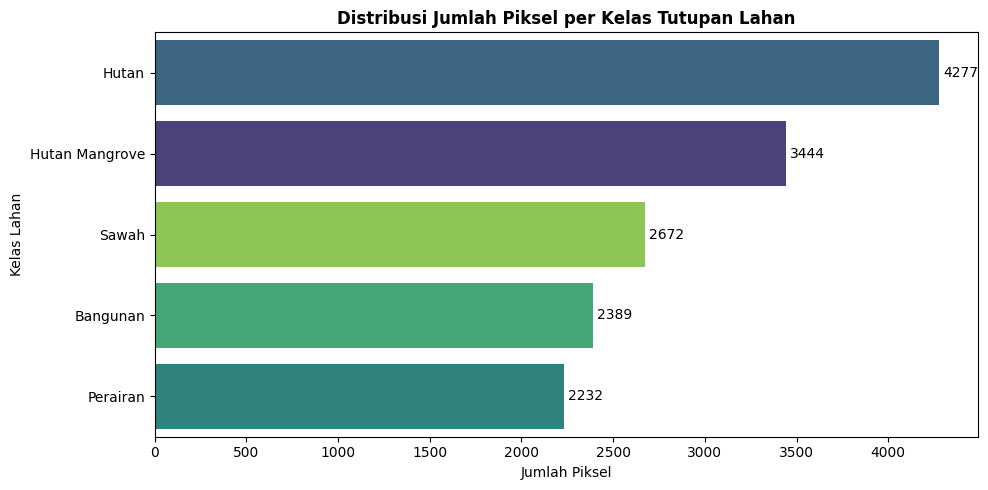

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset_training.csv')

baris, kolom = df.shape
print("Struktur Dataset:")
print(f"Total baris data : {baris}")
print(f"Total kolom      : {kolom} (1 label 'Class', 1 'poly_id', {kolom-2} fitur spektral & indeks)\n")

print("Distribusi Kelas (Jumlah Piksel):")
distribusi = df['Class'].value_counts()
for kelas, jumlah in distribusi.items():
    print(f"- {kelas:<15}: {jumlah} piksel")

print("\nDistribusi Area (Jumlah Poligon Unik):")
poligon_per_kelas = df.groupby('Class')['poly_id'].nunique().sort_values(ascending=False)
for kelas, jumlah_poly in poligon_per_kelas.items():
    print(f"- {kelas:<15}: {jumlah_poly} poligon")

print("\nSamples Data Teratas:")
display(df.head())

# Visualisasi Distribusi Kelas
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    data=df, 
    y='Class', 
    order=distribusi.index, 
    palette='viridis',
    hue='Class',
    legend=False
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + (distribusi.max() * 0.005), p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

### Temuan Kritis (Data Issues)

Berdasarkan hasil ekstraksi data terbaru, perbaikan pada sampel *Region of Interest* (ROI) dan penerapan filter *noise* NDWI telah sukses mengatasi masalah ketimpangan kelas yang ekstrem. Dataset kini sangat representatif dengan total 15.014 piksel valid yang tersebar pada 244 area poligon unik (rata-rata ~50 poligon per kelas). Kelas Perairan yang umumnya mendominasi kini berada di angka 2.232 piksel, sementara representasi Hutan Mangrove berhasil ditingkatkan menjadi 3.444 piksel.

Meski distribusi kelas sudah sangat sehat, tantangan utama pada dataset penginderaan jauh adalah adanya autokorelasi spasial (*Spatial Autocorrelation*), yakni kondisi di mana piksel-piksel yang letaknya bersebelahan di dalam satu poligon cenderung memiliki nilai spektral yang kembar atau sangat mirip. Jika data dibagi secara acak per-piksel (*random pixel split*), model akan mengalami fenomena **Spatial Data Leakage** (kebocoran data). Model akan terlihat jenius dengan akurasi semu (>97%) karena ia hanya diuji menggunakan piksel tetangga yang sudah ia hafal, bukan area yang benar-benar baru.

Untuk mencegah kebocoran spasial tersebut, tahap *Data Preparation* tidak menggunakan pembagian data acak standar, melainkan menerapkan **Spatial Group Split** menggunakan teknik *Stratified Group K-Fold* berbasis ID Poligon (`poly_id`). Pemisahan data latih dan data uji dipotong secara mutlak berdasarkan area poligon (tidak ada piksel dari poligon yang sama yang bocor ke dua tempat sekaligus). 

Selanjutnya, teknik **Undersampling Murni** HANYA akan diaplikasikan pada ruang data latih (*training set*) agar model belajar secara 100% adil dari setiap kelas. Sementara itu, data uji (*testing set*) dibiarkan natural tanpa penyetaraan untuk menguji ketangguhan model di kondisi lapangan yang sesungguhnya.


### Pengecekan Missing Values

Sebelum melangkah ke tahap selanjutnya, perlu dipastikan bahwa seluruh piksel memiliki nilai spektral yang lengkap. Hal ini dilakukan untuk mengidentifikasi adanya data kosong akibat kendala teknis saat perekaman objek, seperti tutupan awan pekat, bayangan awan, atau gangguan pada sensor satelit.

In [15]:
# Memeriksa jumlah data kosong (null/NaN) di setiap kolom
missing_data = df.isnull().sum()
total_missing = missing_data.sum()

print("Jumlah Nilai Kosong per Kolom:")
print(missing_data)
print(f"\nTotal nilai kosong: {total_missing}")

if total_missing == 0:
    print("Dataset bersih dari nilai kosong.")
else:
    print(f"Peringatan: Ditemukan {total_missing} nilai kosong yang perlu ditangani.")

Jumlah Nilai Kosong per Kolom:
Class      0
poly_id    0
Band_2     0
Band_3     0
Band_4     0
Band_8A    0
Band_11    0
Band_12    0
NDVI       0
NDWI       0
dtype: int64

Total nilai kosong: 0
Dataset bersih dari nilai kosong.


## Data Preparation

Tahap ini bertujuan untuk menyiapkan dataset agar optimal sebelum masuk ke proses pemodelan, dengan dua fokus utama: mencegah **Spatial Data Leakage** akibat autokorelasi spasial, dan mengatasi **Class Imbalance** melalui pendekatan *undersampling* murni hingga mencapai proporsi data latih yang 100% seimbang.

| Masalah Data | Dampak Jika Dibiarkan | Solusi yang Diterapkan |
|---|---|---|
| **1. Spatial Autocorrelation (Kebocoran Spasial)** <br><br> Piksel yang saling bersebelahan di dalam satu area poligon cenderung memiliki nilai spektral satelit yang sangat mirip atau kembar. | **Spatial Data Leakage & Akurasi Semu** <br><br> Jika dibagi secara acak per-piksel, model akan diuji menggunakan piksel "bocoran" yang sudah ia hafal dari tetangganya saat proses latih, menghasilkan akurasi palsu >97%. | **Spatial Group Split (Berbasis `poly_id`)** <br><br> Pemisahan data latih (80%) dan data uji (20%) dipotong secara mutlak berdasarkan ID poligon. Tidak ada satupun piksel dari poligon yang sama yang diperbolehkan bocor menyeberang ke kedua set data. |
| **2. Class Imbalance (Ketidakseimbangan Kelas)** <br><br> Meski distribusi telah diperbaiki di tahap sebelumnya, kelas Hutan kini menjadi mayoritas (4.277 piksel), sedangkan Perairan menjadi minoritas (2.232 piksel). | **Bias Mayoritas pada Model** <br><br> Algoritma cenderung *over-predict* pada kelas dominan untuk mencari aman. Kelas minoritas rentan diabaikan demi mendapatkan tingkat akurasi global yang tinggi. | **Undersampling Murni HANYA pada Data Latih** <br><br> Memangkas data kelas mayoritas secara acak agar jumlahnya turun dan setara persis dengan kelas terkecil. Modifikasi ini HANYA dilakukan di ruang data latih agar data uji tetap objektif mewakili realita lapangan (tanpa kloning data sintetis seperti SMOTE). |

Poligon di Data Latih : 203 area
Poligon di Data Uji   : 41 area

Distribusi Data Latih (Sebelum Balancing):
Class
Hutan             3422
Hutan Mangrove    2307
Sawah             2138
Bangunan          1912
Perairan          1786
Name: count, dtype: int64

Distribusi Data Latih (Setelah Undersampling Murni):
Class
Bangunan          1786
Hutan             1786
Hutan Mangrove    1786
Perairan          1786
Sawah             1786
Name: count, dtype: int64


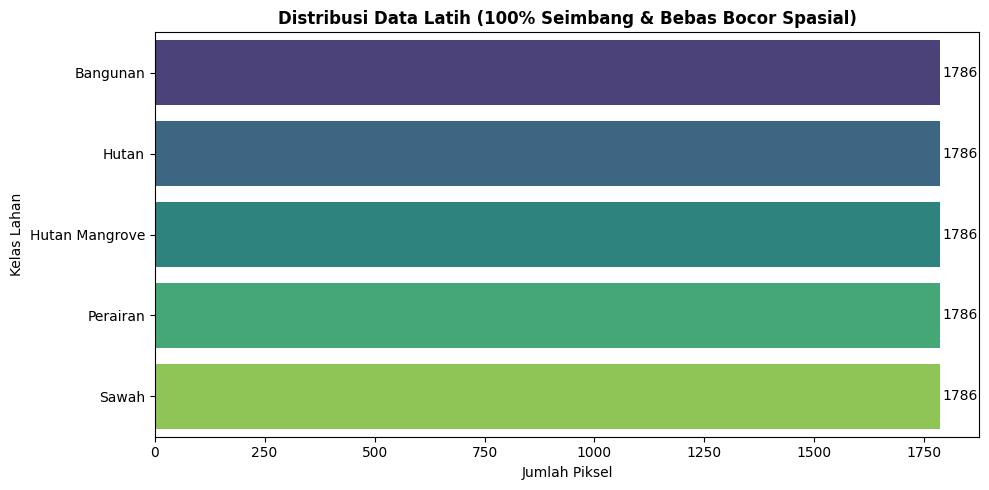

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold
from imblearn.under_sampling import RandomUnderSampler

# Memuat dataset 
df = pd.read_csv('dataset_training.csv').dropna()

# Memisahkan target (y), grup poligon, dan fitur (X)
# poly_id BUKAN fitur spektral, jadi wajib di-drop agar tidak ikut dipelajari model
X = df.drop(columns=['Class', 'poly_id'])
y = df['Class']
groups = df['poly_id']

# Split Spatial per Poligon (5 Lipatan -> 80% Latih, 20% Uji)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Verifikasi Keamanan Kebocoran (Sanity Check)
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx])), "BAHAYA: Ada kebocoran poligon!"
print(f"Poligon di Data Latih : {groups.iloc[train_idx].nunique()} area")
print(f"Poligon di Data Uji   : {groups.iloc[test_idx].nunique()} area\n")

print("Distribusi Data Latih (Sebelum Balancing):")
print(y_train.value_counts())

# Undersampling Murni HANYA pada data latih
under_sampler = RandomUnderSampler(sampling_strategy='auto', random_state=42)
X_train_bal, y_train_bal = under_sampler.fit_resample(X_train, y_train)

print("\nDistribusi Data Latih (Setelah Undersampling Murni):")
print(y_train_bal.value_counts())

# Visualisasi distribusi kelas setelah diseimbangkan
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    y=y_train_bal, 
    palette='viridis', 
    order=y_train_bal.value_counts().index,
    hue=y_train_bal,
    legend=False
)
plt.title('Distribusi Data Latih (100% Seimbang & Bebas Bocor Spasial)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + 5, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

## Modeling

Tahap ini merupakan inti dari seluruh proses pengembangan, di mana algoritma *Machine Learning* dilatih menggunakan data spektral yang telah disiapkan agar mampu mengenali karakteristik unik permukaan bumi dan melakukan klasifikasi tutupan lahan secara otomatis. 

Algoritma utama yang digunakan dalam penelitian ini adalah **Random Forest Classifier**, sebuah metode *ensemble learning* yang sangat tangguh dalam menangani data geospasial karena mampu memodelkan hubungan non-linear yang kompleks antar-band spektral tanpa mudah mengalami *overfitting*.

Model dilatih menggunakan 8 fitur independen (6 band spektral mentah dan 2 indeks kalkulasi, yakni NDVI dan NDWI) pada dataset latih yang telah 100% diseimbangkan (tepat 1.786 piksel per kelas). Karena distribusi kelas kini sudah merata secara fisik menggunakan data observasi satelit murni tanpa kloning sintetis (SMOTE), algoritma tidak lagi memerlukan parameter pembobotan kelas paksa (*algorithmic class weighting*). Konfigurasi parameter seperti kedalaman pohon (*max_depth*) disesuaikan secara proporsional agar model mampu mengekstrak pola batas yang rumit, seperti perbedaan serapan SWIR pada Hutan Mangrove dan Hutan Biasa.

### Konsep Alur Kerja Pemodelan

Proses pemodelan dibagi menjadi dua fase utama untuk memastikan model yang dihasilkan tidak hanya sekadar menghafal data latihan, melainkan juga andal saat memprediksi area baru:

- **Fase Pelatihan (Training):** Algoritma *Random Forest Classifier* dilatih secara eksklusif menggunakan data latih hasil *undersampling* murni. Karena dataset pelatihan sudah 100% seimbang secara jumlah (masing-masing 1.786 piksel per kelas), algoritma dibiarkan belajar secara natural tanpa perlu intervensi pembobotan kelas paksa. Pada tahap ini, model memetakan pola aturan (*decision rules*) berdasarkan 8 fitur kunci (Band 2, Band 3, Band 4, Band 8A, Band 11, Band 12, NDVI, dan NDWI) untuk mengenali setiap kelas lahan.
- **Fase Pengujian (Testing):** Model yang telah selesai dibangun kemudian diuji kemampuannya menggunakan sisa 20% data uji. Data uji ini sangat krusial karena ia tetap dibiarkan dalam kondisi tidak seimbang (*imbalanced*) sesuai dengan distribusi alam aslinya, dan disembunyikan sepenuhnya selama masa pelatihan. Langkah ini bertujuan untuk mengukur performa objektif dan kejujuran model saat dihadapkan pada skenario dunia nyata yang sebenarnya.


### Rincian Data Latih dan Uji

Sebelum proses pelatihan dimulai, penting untuk meninjau kembali rincian dimensi, struktur, serta distribusi kelas dari data latih yang telah diseimbangkan dan data uji yang akan digunakan sebagai validator performa model.

In [17]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Menampilkan informasi dimensi data
print("Dimensi Dataset Pemodelan:")
print(f"Jumlah sampel data latih : {X_train_bal.shape[0]:,}")
print(f"Jumlah sampel data uji   : {X_test.shape[0]:,}")
print(f"Jumlah fitur             : {X_train_bal.shape[1]} (Band_2, Band_3, Band_4, Band_8A, Band_11, Band_12, NDVI, NDWI)\n")

print("Komposisi Kelas Data Latih:")
print(y_train_bal.value_counts())

print("\nSamples Data Latih:")
display(X_train_bal.head())

Dimensi Dataset Pemodelan:
Jumlah sampel data latih : 8,930
Jumlah sampel data uji   : 3,449
Jumlah fitur             : 8 (Band_2, Band_3, Band_4, Band_8A, Band_11, Band_12, NDVI, NDWI)

Komposisi Kelas Data Latih:
Class
Bangunan          1786
Hutan             1786
Hutan Mangrove    1786
Perairan          1786
Sawah             1786
Name: count, dtype: int64

Samples Data Latih:


,Band_2,Band_3,Band_4,Band_8A,Band_11,Band_12,NDVI,NDWI
11384,369.000000,696.000000,403.000000,4327.0,2144.00,963.0,0.829598,-0.722875
10099,686.000000,954.500000,1198.000000,2916.0,3139.50,2541.5,0.417598,-0.506782
12275,1204.500000,1300.500000,1512.500000,1868.5,2485.00,2350.0,0.105294,-0.179236
11481,958.857143,1121.000000,1294.783333,2070.0,2213.50,1987.0,0.230391,-0.297399
10510,1550.111111,1725.333333,1782.000000,1927.5,2541.75,2520.6,0.039224,-0.055345


### Proses Pelatihan Model (Training)

Pada tahap ini, algoritma *Random Forest* diinisialisasi untuk mempelajari pola hubungan antara 8 fitur karakteristik spektral (6 band mentah dan 2 indeks kalkulasi) dengan kelas tutupan lahan pada dataset latih. Konfigurasi model menggunakan beberapa parameter kunci dengan alasan teknis berikut:

| Parameter | Nilai / Konfigurasi | Alasan Teknis dan Fungsi |
|---|---|---|
| **n_estimators** | `100` | Membangun 100 pohon keputusan (*decision trees*) secara paralel. Jumlah ini merupakan titik optimal standar untuk menangkap pola spektral yang kompleks tanpa membebani memori komputasi secara berlebihan. |
| **max_depth** | `15` | Membatasi kedalaman maksimal setiap pohon. Angka 15 cukup dalam untuk mengekstrak pola batas yang rumit (seperti perbedaan serapan air pada Mangrove vs Hutan Biasa), sekaligus mencegah model menghafal data (*overfitting*). |
| **min_samples_leaf** | `2` | Menetapkan batas minimal 2 sampel pada ujung cabang terakhir pohon keputusan. Ini mencegah algoritma membuat aturan ekstrem yang hanya berlaku untuk 1 piksel spesifik, sehingga model lebih general dan kebal terhadap *noise*. |
| **random_state** | `42` | Berfungsi sebagai pengunci keacakan (*seed*). Parameter ini memastikan hasil pembuatan pohon akan selalu konsisten setiap kali kode dijalankan ulang (*reproducible*). |
| **n_jobs** | `-1` | Memerintahkan komputer untuk menggunakan seluruh inti prosesor (*CPU cores*) secara maksimal untuk mempercepat waktu komputasi pelatihan model. |

In [18]:
from sklearn.ensemble import RandomForestClassifier

print("Memulai proses pelatihan model Random Forest...")

# Inisialisasi model 
rf_model = RandomForestClassifier(
    n_estimators=100, 
    max_depth=15,             # Kedalaman ditingkatkan untuk menangkap pola batas yang kompleks
    min_samples_leaf=2,       
    random_state=42, 
    n_jobs=-1
)

# Pelatihan model menggunakan data hasil Undersampling Murni
rf_model.fit(X_train_bal, y_train_bal)

print("Proses pelatihan selesai. Model berhasil dibangun.")

Memulai proses pelatihan model Random Forest...
Proses pelatihan selesai. Model berhasil dibangun.


### MODEL
Setelah dilakukannya training, didapatkanlah model seperti berikut :

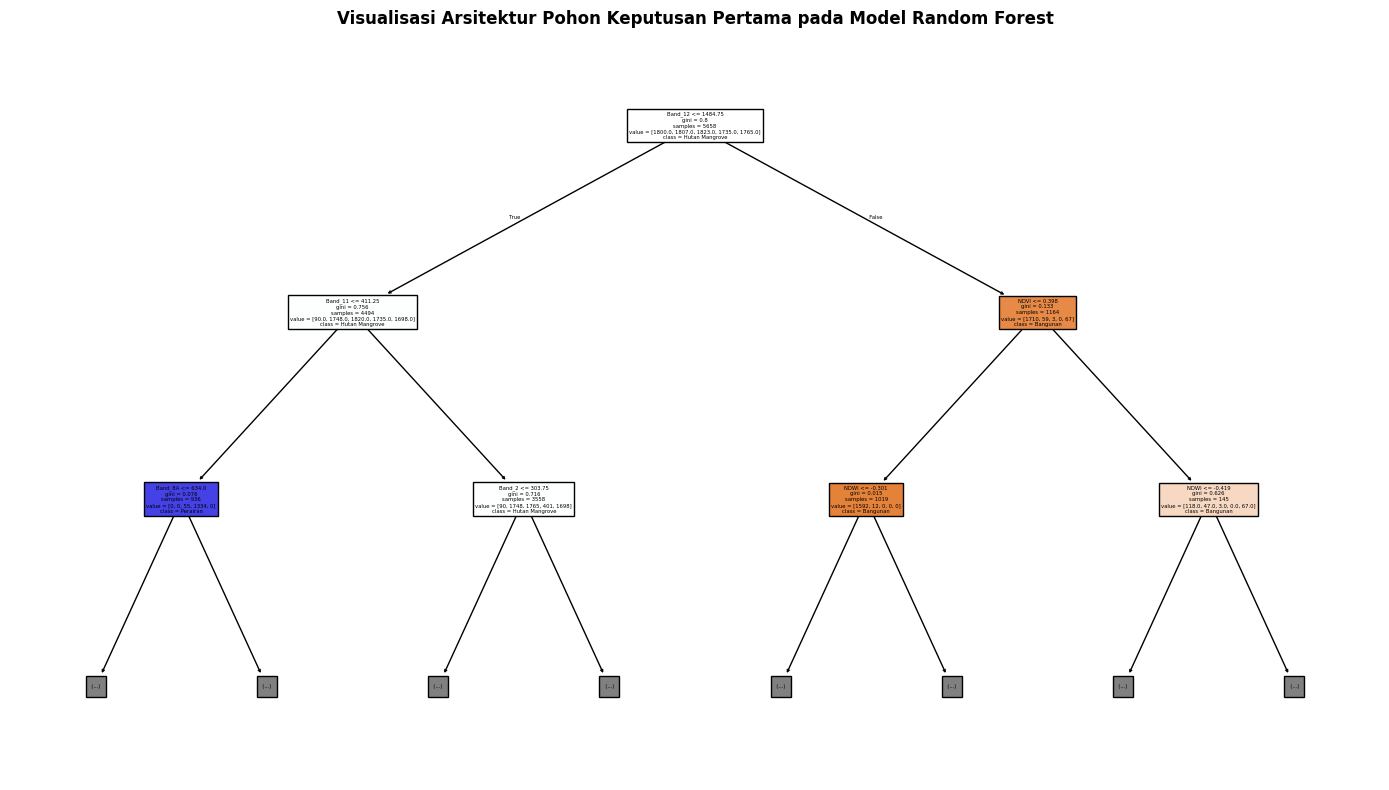

In [19]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Mengekstrak estimator (pohon keputusan) pertama dari ansambel Random Forest
pohon_pertama = rf_model.estimators_[0]

plt.figure(figsize=(14, 8))
plot_tree(
    pohon_pertama, 
    feature_names=['Band_2', 'Band_3', 'Band_4', 'Band_8A', 'Band_11', 'Band_12', 'NDVI', 'NDWI'], 
    class_names=list(rf_model.classes_), 
    filled=True, 
    max_depth=2
) 

plt.title("Visualisasi Arsitektur Pohon Keputusan Pertama pada Model Random Forest", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### Pengujian dan Evaluasi Model

Setelah proses pelatihan selesai, model diuji menggunakan data uji untuk mengevaluasi performa klasifikasinya secara menyeluruh. Pengujian ini penting untuk melihat kemampuan generalisasi model terhadap data baru yang belum pernah dipelajari sebelumnya.

Menjalankan prediksi pada data uji (Area Poligon Baru)...

Akurasi Global (Bisa bias ke Perairan): 65.18%
Balanced Accuracy (Metrik Lebih Jujur)  : 77.36%
Macro F1-Score (Akurasi Rata-rata)      : 68.26%

Laporan Klasifikasi Detail:
                precision    recall  f1-score   support

      Bangunan       0.99      0.98      0.99       477
         Hutan       0.59      0.87      0.71       855
Hutan Mangrove       0.65      0.07      0.13      1137
      Perairan       0.97      0.99      0.98       446
         Sawah       0.45      0.95      0.61       534

      accuracy                           0.65      3449
     macro avg       0.73      0.77      0.68      3449
  weighted avg       0.69      0.65      0.58      3449



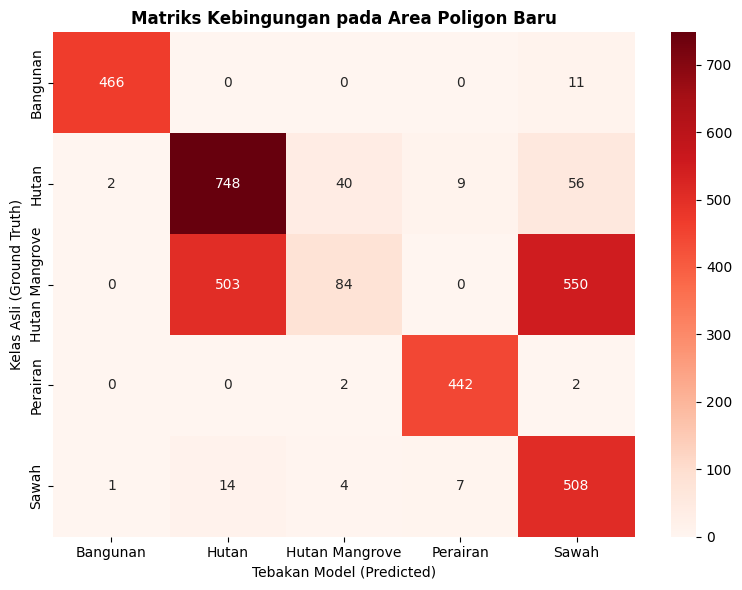


Proses selesai. Model berhasil disimpan sebagai 'model_rf.pkl'


In [20]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, balanced_accuracy_score, f1_score
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

print("Menjalankan prediksi pada data uji (Area Poligon Baru)...")

# Evaluasi model menggunakan data uji murni yang independen dari proses latih
y_pred = rf_model.predict(X_test)

# Menghitung berbagai metrik akurasi
akurasi_global = accuracy_score(y_test, y_pred)
akurasi_seimbang = balanced_accuracy_score(y_test, y_pred)
f1_makro = f1_score(y_test, y_pred, average='macro')

print(f"\nAkurasi Global (Bisa bias ke Perairan): {akurasi_global * 100:.2f}%")
print(f"Balanced Accuracy (Metrik Lebih Jujur)  : {akurasi_seimbang * 100:.2f}%")
print(f"Macro F1-Score (Akurasi Rata-rata)      : {f1_makro * 100:.2f}%\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred))

# Membongkar salah tebak model dengan Matriks Kebingungan
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Reds', 
    xticklabels=rf_model.classes_, 
    yticklabels=rf_model.classes_
)
plt.title('Matriks Kebingungan pada Area Poligon Baru', fontweight='bold')
plt.ylabel('Kelas Asli (Ground Truth)')
plt.xlabel('Tebakan Model (Predicted)')
plt.tight_layout()
plt.show()

# Ekspor hasil pemodelan ke berkas biner pkl
joblib.dump(rf_model, 'model_rf.pkl')
print("\nProses selesai. Model berhasil disimpan sebagai 'model_rf.pkl'")

## DEPLOYMENT


In [23]:
import os
import rasterio
import numpy as np
import joblib
import pandas as pd
from rasterio.windows import Window

input_tif = 'Sentinel2_Jatim_Utuh.tif'
output_tif = 'Hasil_Klasifikasi_LULC.tif'
file_model = 'model_rf.pkl'

if os.path.exists(output_tif):
    print(f"File output '{output_tif}' sudah tersedia. Proses inferensi raster dilewati.")
else:
    print(f"Memuat model Random Forest dari '{file_model}'...")
    rf_model = joblib.load(file_model) 

    print("Membuka citra satelit input...")
    with rasterio.open(input_tif) as src:
        # Siapkan metadata untuk file output
        meta = src.meta.copy()
        meta.update(count=1, dtype=rasterio.uint8, nodata=0) 
        
        baris_total = src.height
        kolom_total = src.width
        print(f"Dimensi citra input: {baris_total} Baris x {kolom_total} Kolom")

        # Kamus konversi kelas
        kamus_warna = {
            'Perairan': 1,
            'Hutan': 2,
            'Hutan Mangrove': 3,
            'Sawah': 4,
            'Bangunan': 5
        }
        nama_fitur = ['Band_2', 'Band_3', 'Band_4', 'Band_8A', 'Band_11', 'Band_12', 'NDVI', 'NDWI']

        # Batasan jumlah baris yang diproses dalam satu waktu (agar memori tidak jebol)
        chunk_size = 1000 
        
        print("Mulai proses klasifikasi secara bertahap (Chunking)...")
        with rasterio.open(output_tif, 'w', **meta) as dst:
            
            # Looping untuk memotong gambar menjadi blok-blok horizontal
            for i in range(0, baris_total, chunk_size):
                tinggi_chunk = min(chunk_size, baris_total - i)
                window = Window(0, i, kolom_total, tinggi_chunk)
                
                # Hanya membaca data pada blok (window) saat ini
                img_data = src.read([1, 2, 3, 4, 5, 6, 7, 8], window=window)
                n_bands, baris, kolom = img_data.shape
                
                img_flatten = img_data.reshape(n_bands, -1).T 

                # Masking piksel background
                mask = (img_flatten[:, 0] > 0)
                
                # Siapkan kanvas kosong untuk hasil blok ini (0 = NoData)
                peta_hasil_chunk = np.zeros(baris * kolom, dtype=np.uint8)

                # Jika di blok ini ada daratan/area yang valid
                if mask.any():
                    data_valid = img_flatten[mask]
                    df_valid = pd.DataFrame(data_valid, columns=nama_fitur)

                    # Prediksi khusus blok ini
                    prediksi_valid = rf_model.predict(df_valid)
                    prediksi_angka = np.vectorize(kamus_warna.get)(prediksi_valid)

                    # Masukkan tebakan ke kanvas
                    peta_hasil_chunk[mask] = prediksi_angka

                # Bentuk ulang ke 2D dan tulis ke file output tepat di posisi bloknya
                peta_hasil_2d = peta_hasil_chunk.reshape(baris, kolom)
                dst.write(peta_hasil_2d, 1, window=window)
                
                print(f"-> Selesai memproses baris {i} sampai {i + tinggi_chunk} dari {baris_total}...")

    print(f"\nProses selesai! Peta klasifikasi se-Jawa Timur berhasil disimpan di: {output_tif}")

Memuat model Random Forest dari 'model_rf.pkl'...
Membuka citra satelit input...
Dimensi citra input: 13866 Baris x 19887 Kolom
Mulai proses klasifikasi secara bertahap (Chunking)...
-> Selesai memproses baris 0 sampai 1000 dari 13866...
-> Selesai memproses baris 1000 sampai 2000 dari 13866...
-> Selesai memproses baris 2000 sampai 3000 dari 13866...
-> Selesai memproses baris 3000 sampai 4000 dari 13866...
-> Selesai memproses baris 4000 sampai 5000 dari 13866...
-> Selesai memproses baris 5000 sampai 6000 dari 13866...
-> Selesai memproses baris 6000 sampai 7000 dari 13866...
-> Selesai memproses baris 7000 sampai 8000 dari 13866...
-> Selesai memproses baris 8000 sampai 9000 dari 13866...
-> Selesai memproses baris 9000 sampai 10000 dari 13866...
-> Selesai memproses baris 10000 sampai 11000 dari 13866...
-> Selesai memproses baris 11000 sampai 12000 dari 13866...
-> Selesai memproses baris 12000 sampai 13000 dari 13866...
-> Selesai memproses baris 13000 sampai 13866 dari 13866...

In [1]:
import rasterio

print("Mulai mengompres peta...")
with rasterio.open('Hasil_Klasifikasi_LULC.tif') as src:
    meta = src.meta.copy()
    
    meta.update(compress='lzw')

    with rasterio.open('Hasil_Klasifikasi_LULC_Kecil.tif', 'w', **meta) as dst:
        dst.write(src.read(1), 1)

print("Selesai! Silakan cek ukuran file 'Hasil_Klasifikasi_LULC_Kecil.tif'")

Mulai mengompres peta...
Selesai! Silakan cek ukuran file 'Hasil_Klasifikasi_LULC_Kecil.tif'


### HASIL STREAMLIT

Untuk melihat hasil pemetaan, masuk ke link berikut :
https://lulc-jatim-app-uts.streamlit.app/